## Import core Libraries

In [2]:
pip install statsforecast utilsforecast

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 

import sys; sys.path.append("..")

from utilsforecast.plotting import plot_series
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import *

warnings.filterwarnings('ignore')
plt.style.use('fivethirtyeight')

In [4]:
df = pd.read_csv("../data/PJME_hourly.csv", parse_dates=True)


In [5]:
df.head()

,Datetime,PJME_MW
0,2002-12-31 01:00:00,26498.0
1,2002-12-31 02:00:00,25147.0
2,2002-12-31 03:00:00,24574.0
3,2002-12-31 04:00:00,24393.0
4,2002-12-31 05:00:00,24860.0


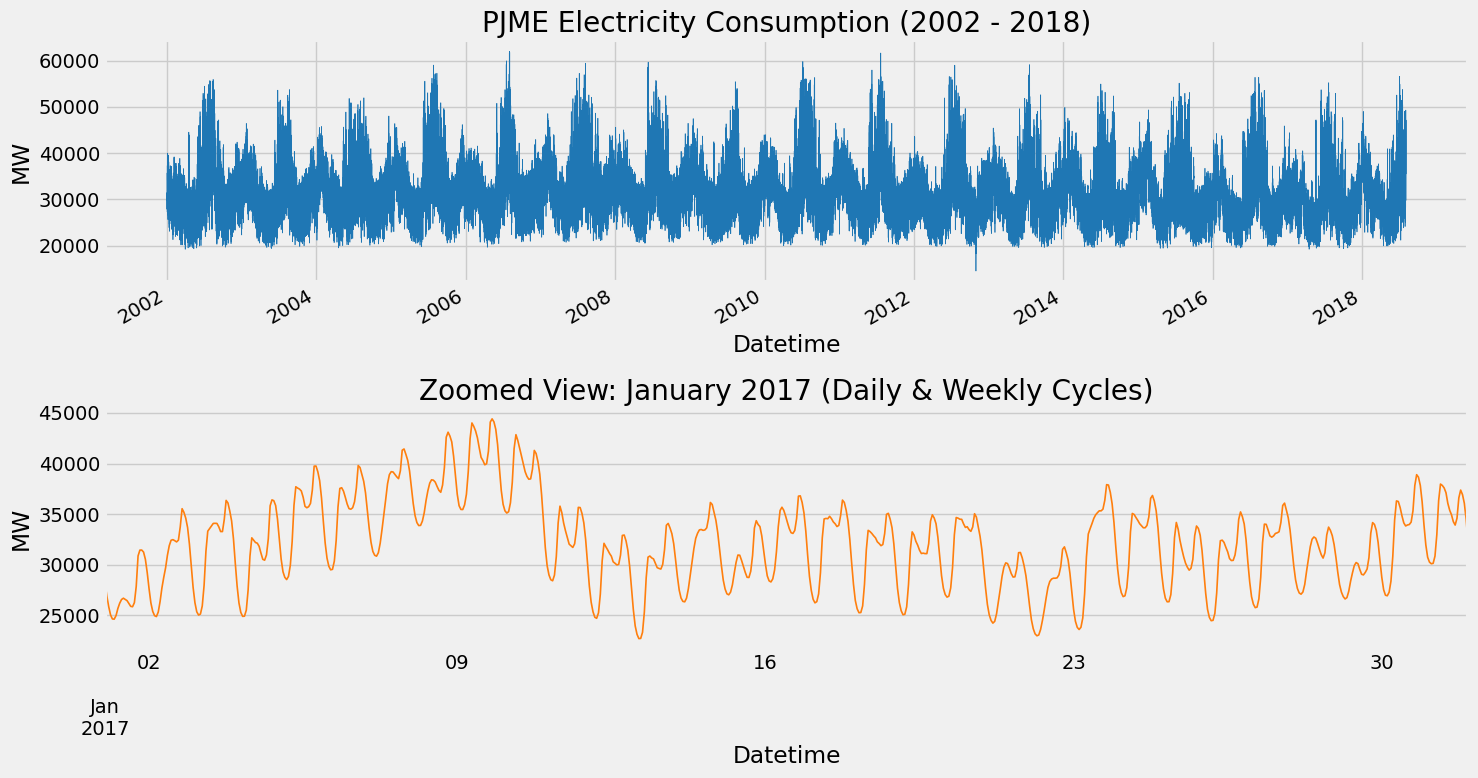

In [10]:
df['Datetime'] = pd.to_datetime(df['Datetime'])
df = df.sort_values('Datetime').set_index('Datetime')

fig, axes = plt.subplots(2, 1, figsize=(15, 8))

# Full history
df['PJME_MW'].plot(ax=axes[0], lw=0.5, color='#1f77b4')
axes[0].set_title('PJME Electricity Consumption (2002 - 2018)')
axes[0].set_ylabel('MW')

# Zoomed 1-month window to see daily & weekly cycles
df.loc['2017-01-01':'2017-01-31', 'PJME_MW'].plot(ax=axes[1], lw=1.2, color='#ff7f0e')
axes[1].set_title('Zoomed View: January 2017 (Daily & Weekly Cycles)')
axes[1].set_ylabel('MW')

plt.tight_layout()
plt.show()

## import cleaned data 

In [2]:
from src.data import load_pjme

In [3]:
df = load_pjme(freq='h')

In [4]:
df.head()

,y
datetime,
2002-01-01 01:00:00,30393.0
2002-01-01 02:00:00,29265.0
2002-01-01 03:00:00,28357.0
2002-01-01 04:00:00,27899.0
2002-01-01 05:00:00,28057.0


## 1. Multi-Level Seasonality Profiles
Analyzing the triple seasonality of electricity demand: **Daily (24h)**, **Weekly (168h)**, and **Annual (12-Month)**.

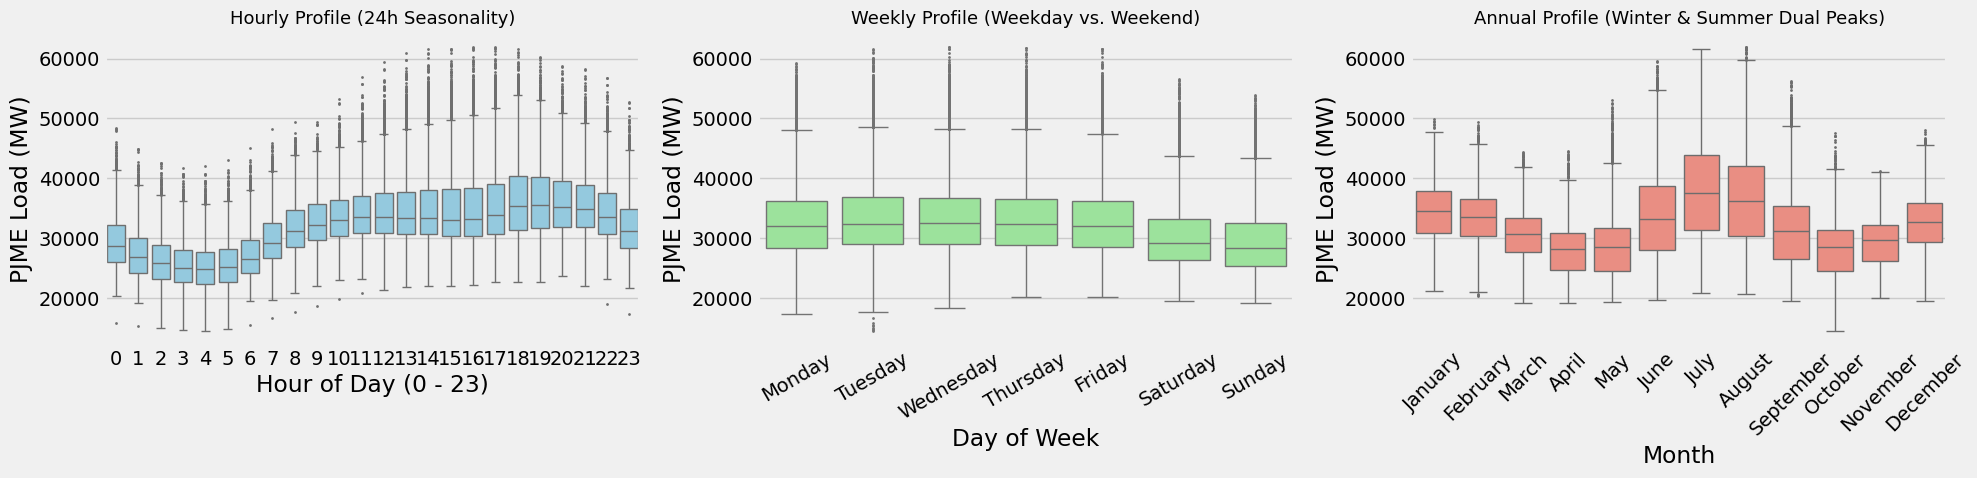

In [5]:
# Feature extraction for seasonality analysis
df_plot = df.copy()
df_plot['hour'] = df_plot.index.hour
df_plot['day_of_week'] = df_plot.index.day_name()
df_plot['month'] = df_plot.index.month_name()
df_plot['year'] = df_plot.index.year

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Daily cycle (24h)
sns.boxplot(data=df_plot, x='hour', y='y', ax=axes[0], color='skyblue', fliersize=1)
axes[0].set_title('Hourly Profile (24h Seasonality)', fontsize=13)
axes[0].set_xlabel('Hour of Day (0 - 23)')
axes[0].set_ylabel('PJME Load (MW)')

# 2. Weekly cycle (Weekday vs. Weekend)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.boxplot(data=df_plot, x='day_of_week', y='y', order=days_order, ax=axes[1], color='lightgreen', fliersize=1)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30)
axes[1].set_title('Weekly Profile (Weekday vs. Weekend)', fontsize=13)
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('PJME Load (MW)')

# 3. Monthly cycle (Winter & Summer peaks)
months_order = ['January', 'February', 'March', 'April', 'May', 'June', 
                'July', 'August', 'September', 'October', 'November', 'December']
sns.boxplot(data=df_plot, x='month', y='y', order=months_order, ax=axes[2], color='salmon', fliersize=1)
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=45)
axes[2].set_title('Annual Profile (Winter & Summer Dual Peaks)', fontsize=13)
axes[2].set_xlabel('Month')
axes[2].set_ylabel('PJME Load (MW)')

plt.tight_layout()
plt.show()

## 2. Average Daily Profile: Weekdays vs. Weekends
Notice the significant drop in demand during weekends due to lower industrial and commercial activity:

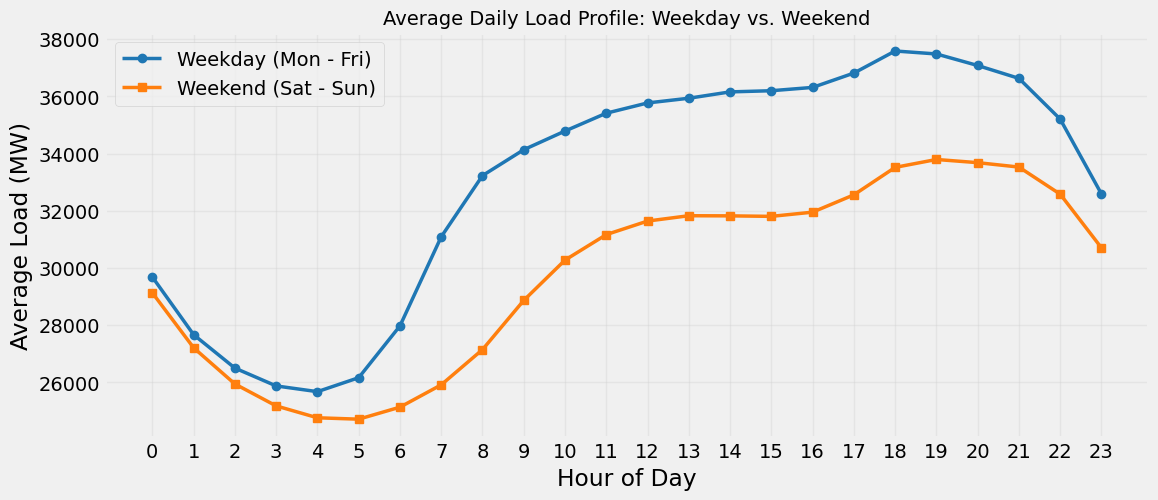

In [12]:
# Compare average hourly curve for weekdays vs weekends
df_plot['is_weekend'] = np.where(df_plot.index.dayofweek.isin([5, 6]), 'Weekend', 'Weekday')
hourly_daytype = df_plot.groupby(['hour', 'is_weekend'])['y'].mean().unstack()

plt.figure(figsize=(12, 5))
plt.plot(hourly_daytype.index, hourly_daytype['Weekday'], label='Weekday (Mon - Fri)', color='#1f77b4', lw=2.5, marker='o')
plt.plot(hourly_daytype.index, hourly_daytype['Weekend'], label='Weekend (Sat - Sun)', color='#ff7f0e', lw=2.5, marker='s')
plt.title('Average Daily Load Profile: Weekday vs. Weekend', fontsize=14)
plt.xlabel('Hour of Day')
plt.ylabel('Average Load (MW)')
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## 3. Distribution & Summary Statistics
Examining the load distribution, density, and key statistical characteristics:

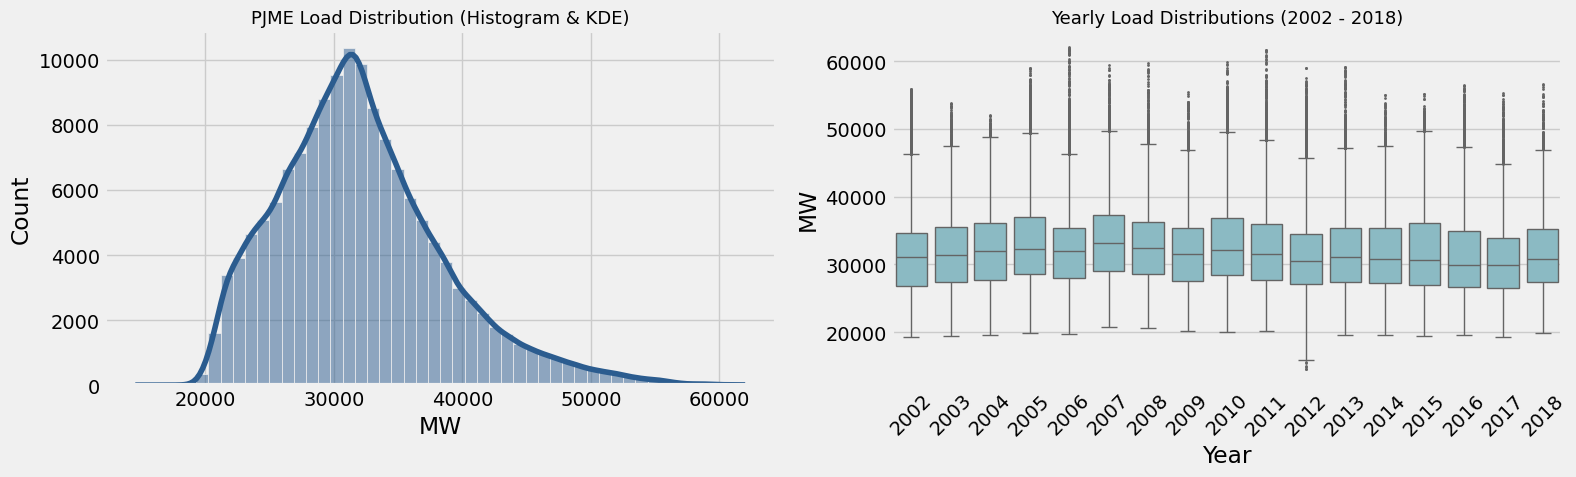

PJME Summary Statistics:
count    145392.000000
mean      32078.927654
std        6464.283311
min       14544.000000
25%       27571.000000
50%       31420.000000
75%       35647.000000
max       62009.000000
Name: y, dtype: float64
Skewness: 0.7390
Kurtosis: 0.7365


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribution Histogram + KDE
sns.histplot(df['y'], kde=True, ax=axes[0], color='#2b5c8f', bins=50)
axes[0].set_title('PJME Load Distribution (Histogram & KDE)', fontsize=13)
axes[0].set_xlabel('MW')

# Yearly trend comparison
sns.boxplot(data=df_plot, x='year', y='y', ax=axes[1], color='#82c0cc', fliersize=1)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
axes[1].set_title('Yearly Load Distributions (2002 - 2018)', fontsize=13)
axes[1].set_xlabel('Year')
axes[1].set_ylabel('MW')

plt.tight_layout()
plt.show()

print("PJME Summary Statistics:")
print(df['y'].describe())
print(f"Skewness: {df['y'].skew():.4f}")
print(f"Kurtosis: {df['y'].kurtosis():.4f}")

## 4. Time Series Decomposition (Trend, Seasonality, Residuals)
Decomposing 1 year of hourly data (2017) to observe the daily (24h) seasonal cycle and trend line:

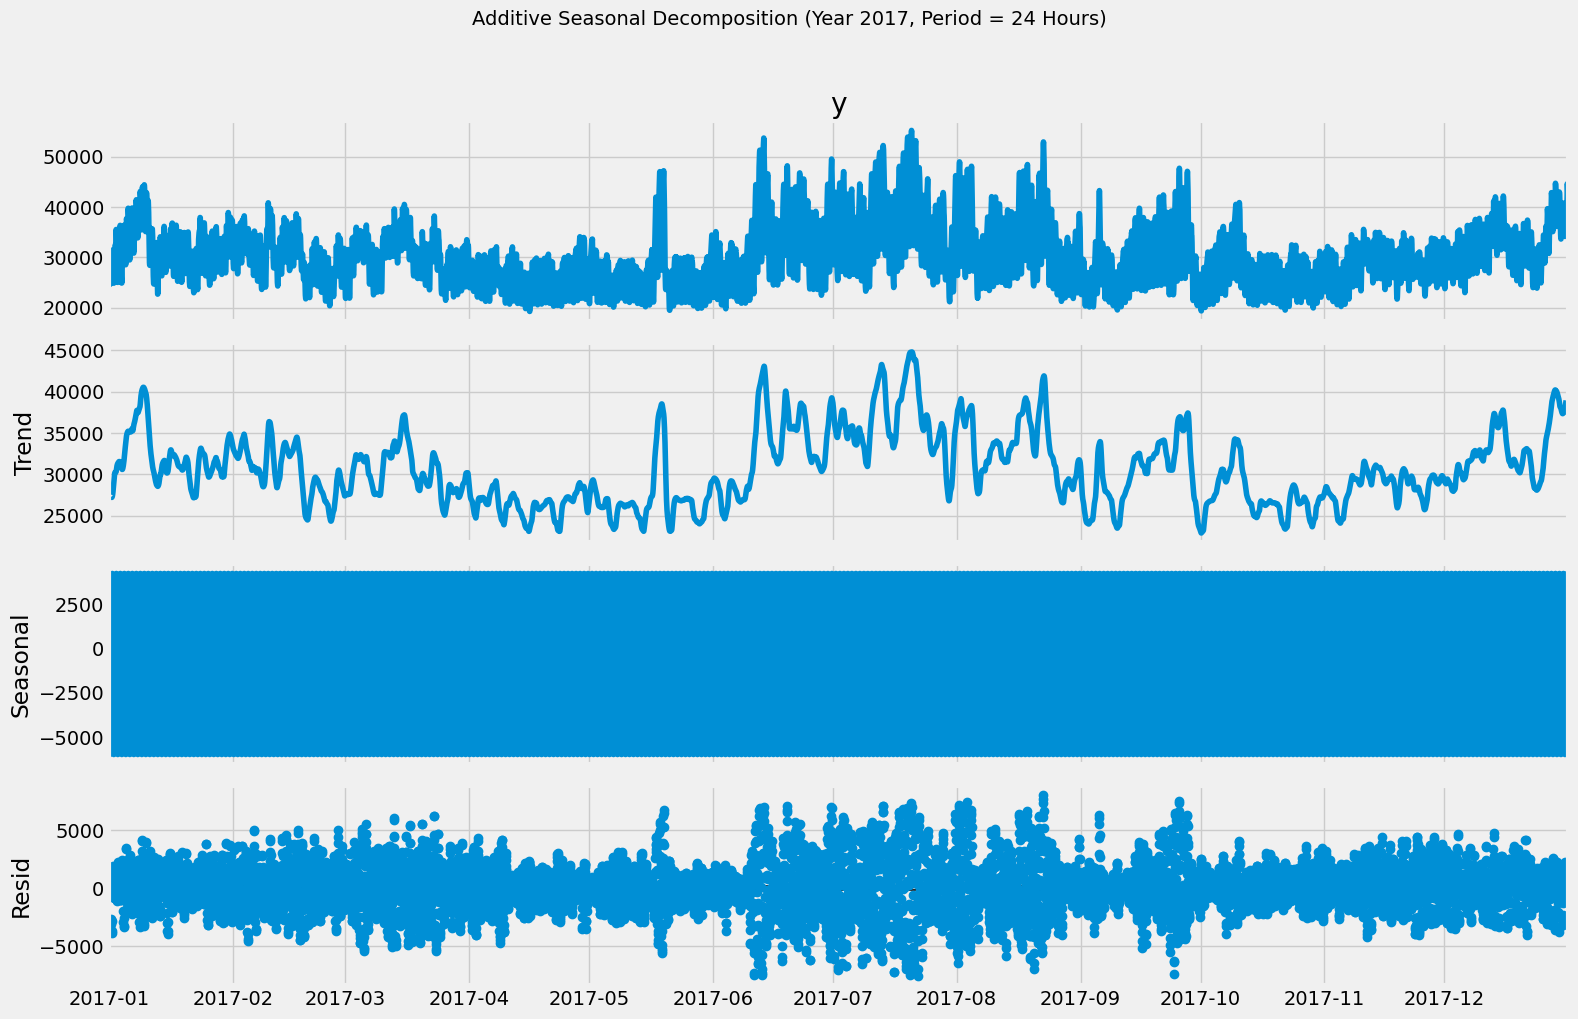

In [9]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose 2017 hourly consumption with daily period=24
decomp = seasonal_decompose(df.loc['2017', 'y'], model='additive', period=24)

fig = decomp.plot()
fig.set_size_inches(16, 10)
fig.suptitle('Additive Seasonal Decomposition (Year 2017, Period = 24 Hours)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 5. Autocorrelation (ACF) & Partial Autocorrelation (PACF)
- **ACF**: Checks recurring cyclical lags (lags 24, 48, 72, 168).
- **PACF**: Informs AR lag feature selection ($t-1, t-2, t-24$) for ML models:

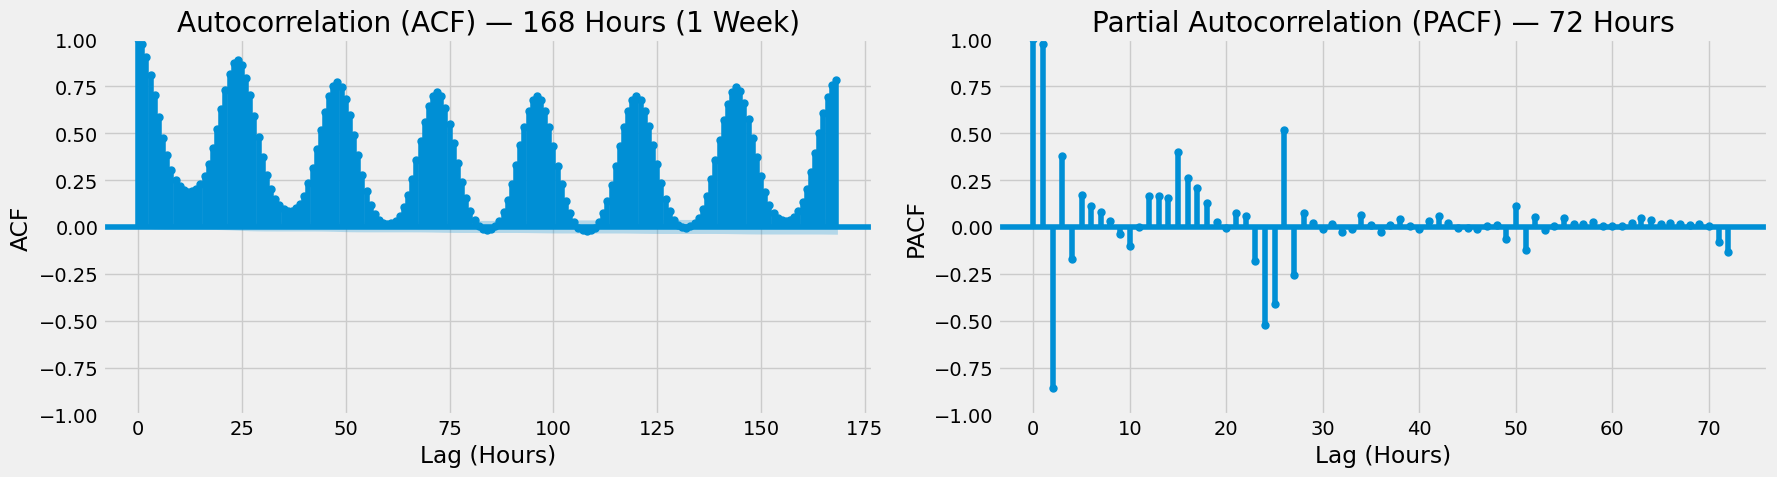

In [10]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# 168 lags = 1 full week of hourly data
plot_acf(df['y'].dropna(), lags=168, ax=axes[0], title='Autocorrelation (ACF) — 168 Hours (1 Week)')
axes[0].set_xlabel('Lag (Hours)')
axes[0].set_ylabel('ACF')

# 72 lags = 3 days
plot_pacf(df['y'].dropna(), lags=72, ax=axes[1], title='Partial Autocorrelation (PACF) — 72 Hours')
axes[1].set_xlabel('Lag (Hours)')
axes[1].set_ylabel('PACF')

plt.tight_layout()
plt.show()

## 6. Stationarity Tests (ADF & KPSS)
Evaluating whether differencing is required prior to applying statistical models:

In [11]:
from statsmodels.tsa.stattools import adfuller, kpss

# Sample or subset for fast and stable testing
sample_series = df['y'].iloc[-24*365:]  # Last 1 year of hourly data

print("=== Augmented Dickey-Fuller (ADF) Test ===")
adf_res = adfuller(sample_series)
print(f"ADF Statistic : {adf_res[0]:.4f}")
print(f"p-value       : {adf_res[1]:.4e}")
print("Stationary" if adf_res[1] < 0.05 else "Non-Stationary (Differencing needed)")

print("\n=== Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test ===")
kpss_res = kpss(sample_series, regression='c', nlags='auto')
print(f"KPSS Statistic: {kpss_res[0]:.4f}")
print(f"p-value       : {kpss_res[1]:.4e}")
print("Non-Stationary (Null rejected)" if kpss_res[1] < 0.05 else "Stationary")

=== Augmented Dickey-Fuller (ADF) Test ===
ADF Statistic : -6.9222
p-value       : 1.1390e-09
Stationary

=== Kwiatkowski-Phillips-Schmidt-Shin (KPSS) Test ===
KPSS Statistic: 0.9241
p-value       : 1.0000e-02
Non-Stationary (Null rejected)


C:\Users\yoga\AppData\Local\Temp\ipykernel_8416\811261462.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_res = kpss(sample_series, regression='c', nlags='auto')


## Appliying Base Models 